<a href="https://colab.research.google.com/github/GautamPandit2405/student-performance-analytics/blob/main/notebooks/student_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

data = [
    [101, "Aarav", "Mathematics", 82, 92, 12],
    [101, "Aarav", "Science", 76, 92, 12],
    [101, "Aarav", "English", 88, 92, 12],
    [102, "Diya", "Mathematics", 91, 97, 15],
    [102, "Diya", "Science", 89, 97, 15],
    [102, "Diya", "English", 93, 97, 15],
    [103, "Kabir", "Mathematics", 65, 78, 7],
    [103, "Kabir", "Science", 70, 78, 7],
    [103, "Kabir", "English", 68, 78, 7],
    [104, "Meera", "Mathematics", 74, 85, 9],
    [104, "Meera", "Science", 81, 85, 9],
    [104, "Meera", "English", 79, 85, 9],
    [105, "Ishaan", "Mathematics", 56, 68, 5],
    [105, "Ishaan", "Science", 61, 68, 5],
    [105, "Ishaan", "English", 59, 68, 5],
    [106, "Anaya", "Mathematics", 87, 94, 13],
    [106, "Anaya", "Science", 90, 94, 13],
    [106, "Anaya", "English", 84, 94, 13],
    [107, "Reyansh", "Mathematics", 72, 82, 8],
    [107, "Reyansh", "Science", 75, 82, 8],
    [107, "Reyansh", "English", 71, 82, 8],
    [108, "Sara", "Mathematics", 95, 98, 16],
    [108, "Sara", "Science", 92, 98, 16],
    [108, "Sara", "English", 96, 98, 16],
]

columns = [
    "student_id", "student_name", "subject",
    "marks", "attendance_pct", "study_hours_week"
]

df = pd.DataFrame(data, columns=columns)

df.to_csv("student_performance.csv", index=False)

print("Dataset created successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset created successfully!
Rows and columns: (24, 6)


,student_id,student_name,subject,marks,attendance_pct,study_hours_week
0,101,Aarav,Mathematics,82,92,12
1,101,Aarav,Science,76,92,12
2,101,Aarav,English,88,92,12
3,102,Diya,Mathematics,91,97,15
4,102,Diya,Science,89,97,15


In [2]:
from google.colab import files

files.download("student_performance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import pandas as pd

df = pd.read_csv("student_performance.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (24, 6)

Column names:
['student_id', 'student_name', 'subject', 'marks', 'attendance_pct', 'study_hours_week']

First 5 rows:


,student_id,student_name,subject,marks,attendance_pct,study_hours_week
0,101,Aarav,Mathematics,82,92,12
1,101,Aarav,Science,76,92,12
2,101,Aarav,English,88,92,12
3,102,Diya,Mathematics,91,97,15
4,102,Diya,Science,89,97,15



Missing values:
student_id          0
student_name        0
subject             0
marks               0
attendance_pct      0
study_hours_week    0
dtype: int64

Duplicate rows: 0

Data types:
student_id           int64
student_name        object
subject             object
marks                int64
attendance_pct       int64
study_hours_week     int64
dtype: object


In [5]:
# 1. Check for missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Remove duplicate rows
df = df.drop_duplicates()

# 3. Check for invalid values
print("Invalid marks:", (~df["marks"].between(0, 100)).sum())
print("Invalid attendance:", (~df["attendance_pct"].between(0, 100)).sum())

# 4. Calculate key performance indicators
print("\n--- Student Performance KPIs ---")
print("Total students:", df["student_id"].nunique())
print("Total subject records:", len(df))
print("Average marks:", round(df["marks"].mean(), 2))
print("Average attendance:", round(df["attendance_pct"].mean(), 2), "%")

# 5. Subject-wise performance
subject_summary = df.groupby("subject")["marks"].mean().round(2)
print("\nAverage marks by subject:")
display(subject_summary)

# 6. Student-wise performance
student_summary = (
    df.groupby(["student_id", "student_name"])
    .agg(
        average_marks=("marks", "mean"),
        attendance_pct=("attendance_pct", "first"),
        study_hours_week=("study_hours_week", "first")
    )
    .round(2)
    .reset_index()
)

display(student_summary)

Missing values:
student_id          0
student_name        0
subject             0
marks               0
attendance_pct      0
study_hours_week    0
dtype: int64
Invalid marks: 0
Invalid attendance: 0

--- Student Performance KPIs ---
Total students: 8
Total subject records: 24
Average marks: 78.92
Average attendance: 86.75 %

Average marks by subject:


,marks
subject,
English,79.75
Mathematics,77.75
Science,79.25


,student_id,student_name,average_marks,attendance_pct,study_hours_week
0,101,Aarav,82.00,92,12
1,102,Diya,91.00,97,15
2,103,Kabir,67.67,78,7
3,104,Meera,78.00,85,9
4,105,Ishaan,58.67,68,5
5,106,Anaya,87.00,94,13
6,107,Reyansh,72.67,82,8
7,108,Sara,94.33,98,16


Missing values:
student_id          0
student_name        0
subject             0
marks               0
attendance_pct      0
study_hours_week    0
dtype: int64
Invalid marks: 0
Invalid attendance: 0

--- Student Performance KPIs ---
Total students: 8
Total subject records: 24
Average marks: 78.92
Average attendance: 86.75 %

Average marks by subject:


,marks
subject,
English,79.75
Mathematics,77.75
Science,79.25


,student_id,student_name,average_marks,attendance_pct,study_hours_week
0,101,Aarav,82.00,92,12
1,102,Diya,91.00,97,15
2,103,Kabir,67.67,78,7
3,104,Meera,78.00,85,9
4,105,Ishaan,58.67,68,5
5,106,Anaya,87.00,94,13
6,107,Reyansh,72.67,82,8
7,108,Sara,94.33,98,16


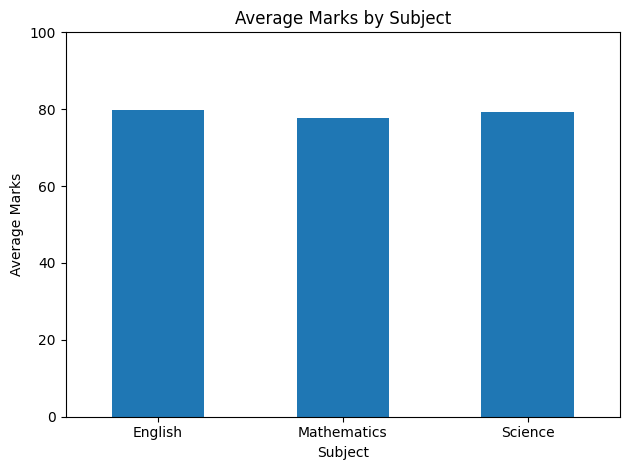

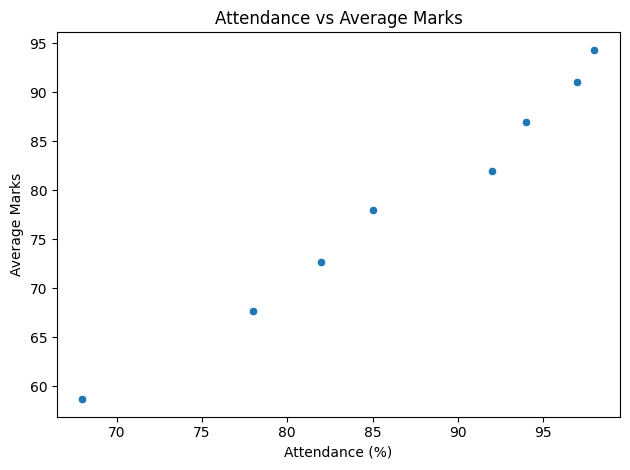

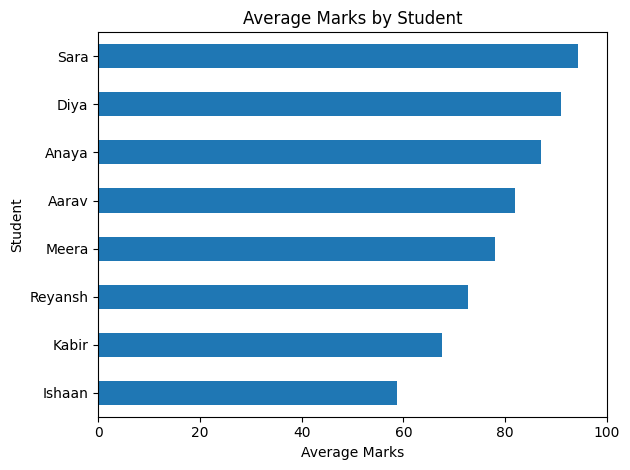

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: Average marks by subject
subject_avg = df.groupby("subject")["marks"].mean()

subject_avg.plot(kind="bar", title="Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 2: Attendance vs Marks
student_avg = df.groupby("student_id").agg(
    attendance=("attendance_pct", "first"),
    average_marks=("marks", "mean")
)

sns.scatterplot(
    data=student_avg,
    x="attendance",
    y="average_marks"
)
plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

# Chart 3: Average marks by student
student_summary = df.groupby("student_name")["marks"].mean().sort_values()

student_summary.plot(kind="barh", title="Average Marks by Student")
plt.xlabel("Average Marks")
plt.ylabel("Student")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

1. Subject performance: English has the highest average marks among the three subjects, while Mathematics has the lowest average.
2. Attendance and achievement: Students with higher attendance generally show higher average marks in this small dataset. This is an observed association, not proof that attendance causes better performance.
3. Variation between students: Performance differs across students, highlighting the potential value of identifying students who may benefit from additional academic support.